In [1]:
%pip install opencv-python matplotlib numpy

   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/44.0 MB 246.6 kB/s eta 0:02:57
   ---------------------------------------- 0.5/44.0 MB 246.6 kB/s eta 0:02:57
   ---------------------------------------- 0.5/44.0 MB 246.6 kB/s eta 0:02:57
   ---------------------------------------- 0.5/44.0 MB 246.6 kB/s eta 0:02:57
    --------------------------------------- 0.8/44.0 M

Could not find platform independent libraries <prefix>

[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Ukuran gambar (tinggi, lebar, kanal): (625, 491, 3)


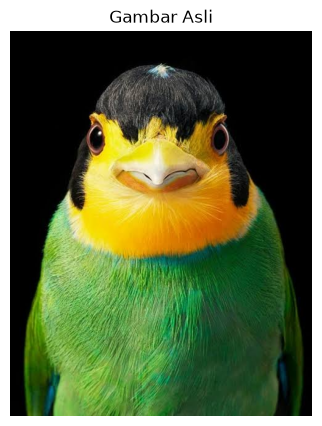

In [7]:
import cv2
import matplotlib.pyplot as plt
image_path = "foto.jpg"  # GANTI dengan nama file gambar kamu

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(
        f"Gambar '{image_path}' tidak ditemukan. "
        "Letakkan gambar di folder notebook atau ubah image_path."
    )

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("Ukuran gambar (tinggi, lebar, kanal):", image.shape)

plt.figure(figsize=(8, 5))
plt.imshow(image_rgb)
plt.title("Gambar Asli")
plt.axis("off")
plt.show()

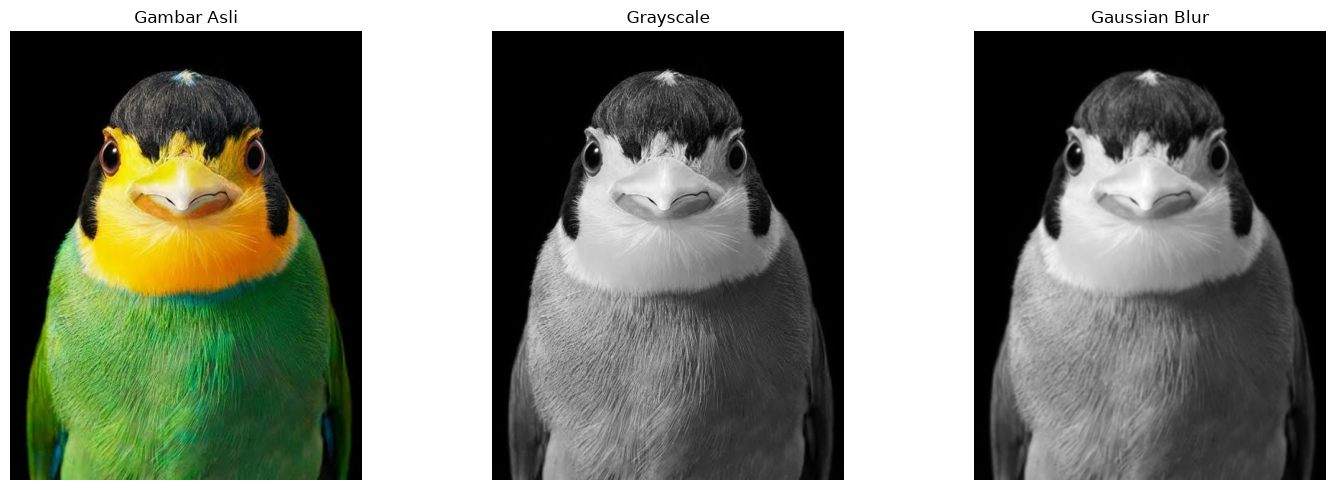

In [8]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(image_rgb)
axes[0].set_title("Gambar Asli")
axes[1].imshow(gray, cmap="gray")
axes[1].set_title("Grayscale")
axes[2].imshow(blurred, cmap="gray")
axes[2].set_title("Gaussian Blur")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

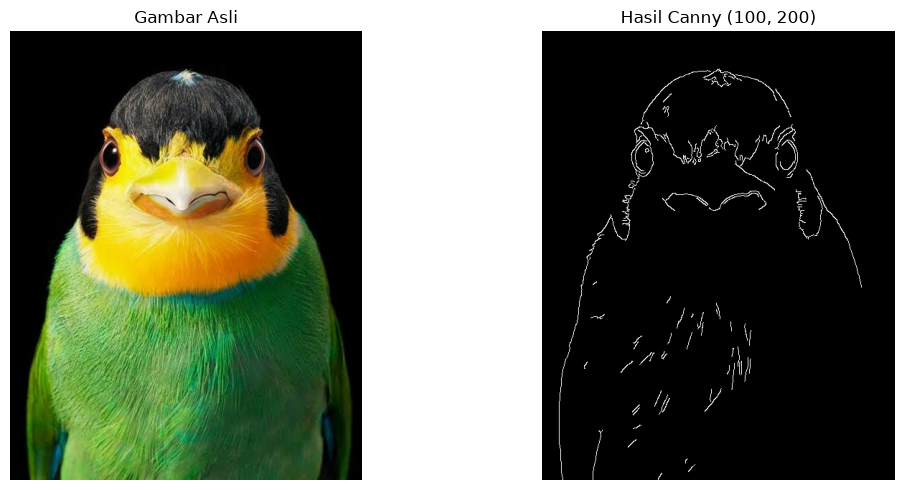

In [9]:
threshold1 = 100
threshold2 = 200

edges_canny = cv2.Canny(blurred, threshold1, threshold2)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image_rgb)
axes[0].set_title("Gambar Asli")
axes[1].imshow(edges_canny, cmap="gray")
axes[1].set_title(f"Hasil Canny ({threshold1}, {threshold2})")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [11]:
import numpy as np
total_pixels = edges_canny.size
edge_pixels = np.count_nonzero(edges_canny)
edge_percentage = edge_pixels / total_pixels * 100

print(f"Total piksel gambar: {total_pixels:,}")
print(f"Piksel tepi yang terdeteksi: {edge_pixels:,}")
print(f"Persentase piksel tepi: {edge_percentage:.2f}%")

Total piksel gambar: 306,875
Piksel tepi yang terdeteksi: 4,495
Persentase piksel tepi: 1.46%


In [16]:
from pathlib import Path 
output_dir = Path("hasil_edge_detection")
output_dir.mkdir(exist_ok=True)

cv2.imwrite(str(output_dir / "grayscale.png"), gray)
cv2.imwrite(str(output_dir / "hasil_canny.png"), edges_canny)

print("Hasil disimpan di:", output_dir.resolve())
print("File:", [p.name for p in output_dir.iterdir()])

Hasil disimpan di: D:\Documents\Matkul_Semester_5\Pengolahan Citra Digital\Tugas\Pengolahan-Citra-Digital\Tugas2\hasil_edge_detection
File: ['grayscale.png', 'hasil_canny.png']


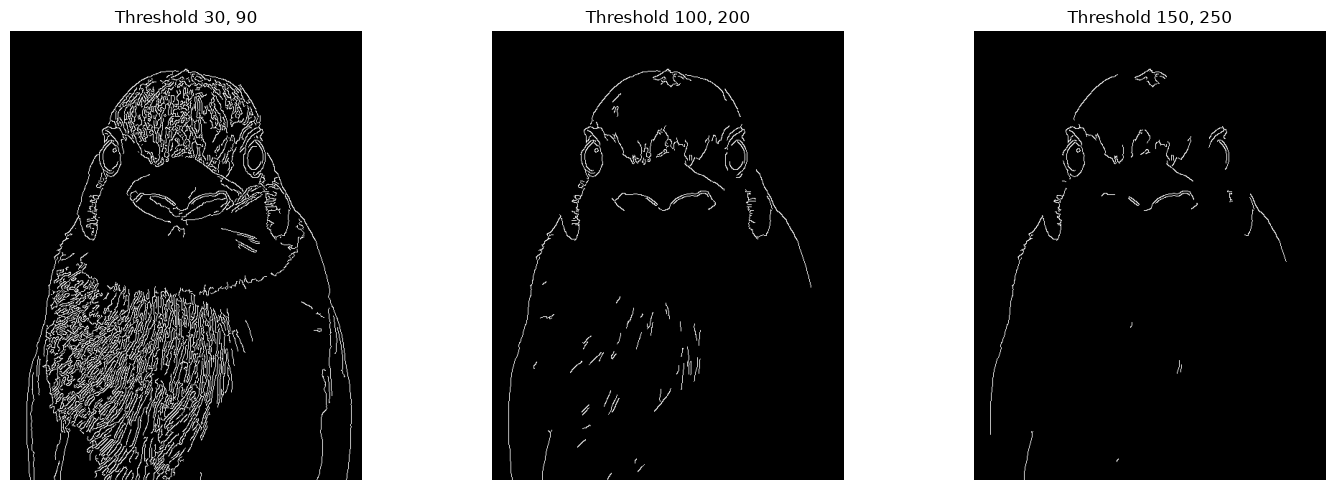

In [17]:
thresholds = [(30, 90), (100, 200), (150, 250)]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (low, high) in zip(axes, thresholds):
    result = cv2.Canny(blurred, low, high)
    ax.imshow(result, cmap="gray")
    ax.set_title(f"Threshold {low}, {high}")
    ax.axis("off")

plt.tight_layout()
plt.show()

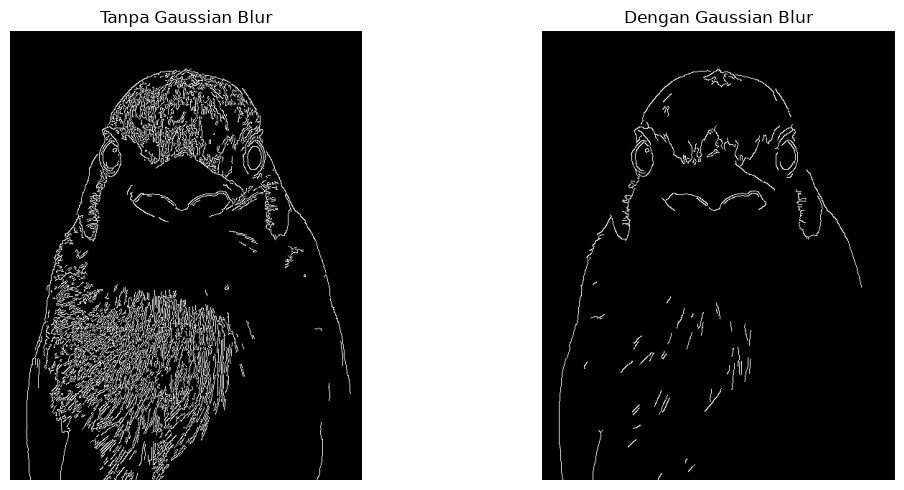

In [18]:
tanpa_blur = cv2.Canny(gray, 100, 200)
dengan_blur = cv2.Canny(blurred, 100, 200)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(tanpa_blur, cmap="gray")
plt.title("Tanpa Gaussian Blur")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(dengan_blur, cmap="gray")
plt.title("Dengan Gaussian Blur")
plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
jumlah_tepi = np.count_nonzero(edges)
total_piksel = edges.size

persentase = jumlah_tepi / total_piksel * 100

print("Jumlah piksel tepi:", jumlah_tepi)
print(f"Persentase piksel tepi: {persentase:.2f}%")

NameError: name 'edges' is not defined